# Pumping, valves and the circulation program

How can a circulation program move blood around without creating or losing it?

Fall 2024.


# Pumping, valves and a circulation program
Predict when a forward valve should close. Predict whether changing ventricular volume requires a changing six-region total. The parameters are synthetic and the baseline has no feedback controller.

{'max_total_drift_L': 1.1031175972675555e-12, 'max_balance_residual_L_min': 3.66819907782201e-11, 'max_solves': 2, 'initial_total_L': 5.136159999999999, 'rate_bpm': 80.0, 'rs_mmHg_min_L': 17.86, 'dt_s': 0.001875, 'independent_balance_residual_L_min': 3.668210180052256e-11, 'coarse_fine_pressure_gap_mmHg': 0.030843520199780983, 'forward_valve_formula_pass': True, 'matched_phase_storage_pass': True, 'invalid_valve_inputs_rejected': 5, 'first_step_transfer_example_mL': 10.0}


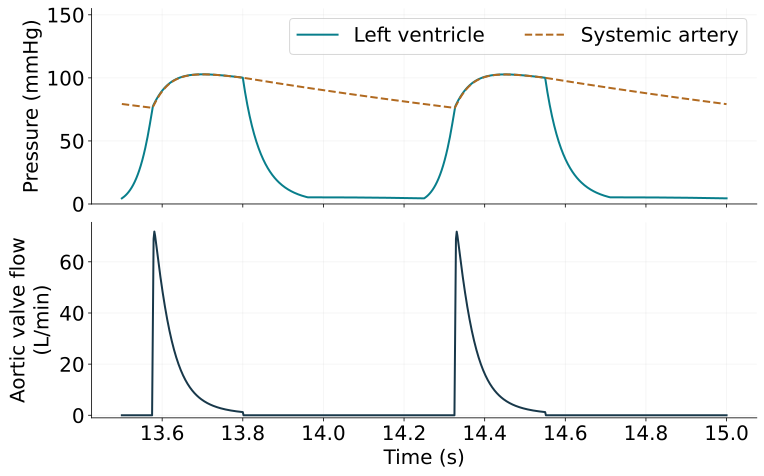

In [1]:
from demo import run, ideal_valve
from circulation import baseline
from IPython.display import SVG, display
import numpy as np
results = run()
print(results)
display(SVG(filename='pressure-and-valve.svg'))

Interpret: identify a time when ventricular pressure is below systemic arterial pressure. Read the aortic flow at that time. Explain the direction rule before changing any code.

110 90 mmHg -> 10.0 L/min
90 110 mmHg -> 0.0 L/min
90 90 mmHg -> 0.0 L/min


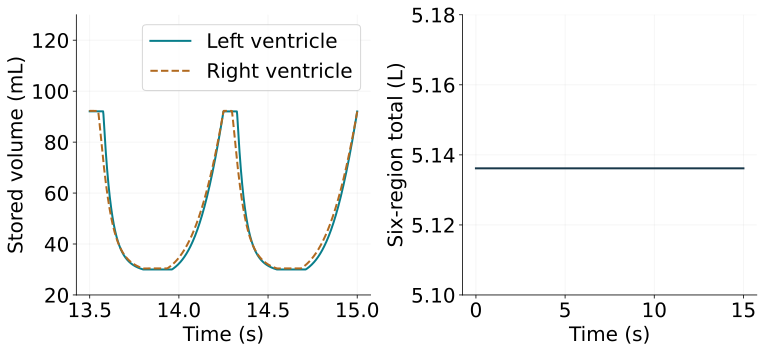

Initial liters: 5.136159999999999
Maximum drift in liters: 1.1031175972675555e-12


In [2]:
for up, down in [(110,90),(90,110),(90,90)]:
    print(up, down, 'mmHg ->', ideal_valve(up,down,2), 'L/min')
display(SVG(filename='changing-storage.svg'))
saved = np.load('circulation.npz')
total = saved['volume_L'].sum(axis=1)
print('Initial liters:', total[0])
print('Maximum drift in liters:', np.max(abs(total-total[0])))

Read and annotate the driver: find initialization, the outer time loop, phase, the pressure-solver call, and stored-volume reconstruction. The inner valve-consistency loop lives in hydraulic_core.py; it retries a single step without advancing physical time.

In [3]:
import inspect
print(inspect.getsource(baseline))
coarse = baseline(duration_s=1.5, dt_s=.001875)
fine = baseline(duration_s=1.5, dt_s=.0009375)
print('Endpoint pressure gap (mmHg):', np.max(abs(coarse['pressure_mmHg'][-1]-fine['pressure_mmHg'][-1])))

def baseline(duration_s=15.,dt_s=.001875,rate_bpm=80.,rs=17.86):
    values=np.array([duration_s,dt_s,rate_bpm,rs],float)
    if not np.isfinite(values).all() or np.any(values<=0):raise ValueError('Use finite positive duration, step, rate and resistance.')
    if duration_s/dt_s>250000:raise ValueError('Baseline workshop limit:250000 steps.')
    p=Parameters(f0=rate_bpm,rs_rest=rs);p.validate()
    n=math.ceil(duration_s/dt_s);times=np.minimum(np.arange(n+1)*dt_s,duration_s)
    c=compliance(0);pressure=P_INITIAL.copy();valves=np.zeros(4,bool);pressures=[pressure.copy()];volumes=[VD+c*pressure];flows=[edge_flows(pressure,rs,p)];max_residual=0.;max_solves=0
    for old,new in zip(times[:-1],times[1:]):
        cn=compliance(rate_bpm*new/60.)
        pressure,valves,q,residual,solves=pressure_step(pressure,c,cn,(new-old)/60.,rs,p,valves)
        c=cn;pressures.append(pressure.copy());volumes.append(VD+c*pressure);flows.append(q)
        max_residual=max(max_residual,float(np.max(abs(res

Endpoint pressure gap (mmHg): 0.030843520199780983


Modify and conclude: predict how changing the time step differs from changing resistance. If exploring another setting, change one choice and record it. Explain why a conserved total alone cannot validate the pressure waveform against a real circulation.